**Questions**
---
How large and sparse is the network? How does cleaning change it?

**Topics Covered**:
* Vertex Degree,
* Degree Sequence and Distribution
* Handshaking theorem,
* Graph Density
* Effects of removing vertices/edges

**Expected Coverage**:
* Node/edge Counts
* Density,
* Degree Statitics and Distribution
* Justify self-loop, low-degree.
* Compare Original vs Processed Graph

## **Libraries and Fixed Variables**

In [283]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

routesFile      = "../data/routes.dat"
routeCols       = ["airline", "airline_id", 
                   "src", "src_id", "dst", "dst_id",
                   "codeshare", "stops", "equipment",]

airlinesFile    = "../data/airlines.dat"
airlineCols     = ["Airline ID", "Name", "Alias", "IATA", "ICAO", 
                   "Callsign", "Country", "Active"]

airportsFile    = "../data/airports.dat"
airportCols     = ['Airport ID', 'Name', 'City', 'Country', 'IATA', 'ICAO', 
                   'Latitude', 'Longitude', 'Altitude', 
                   'Timezone', 'DST', 'Tz database time zone', 'Type', 'Source']


## **Load Data**

In [306]:
routesDataRaw = pd.read_csv(routesFile, header=None, names=routeCols, na_values="\\N", keep_default_na=False)
display(routesDataRaw)

# routesDataRaw["frequency"] = routesDataRaw.groupby(["src", "dst"])["src"].transform("size")
# display(routesDataRaw[routesDataRaw["frequency"] == 1].head())

,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment
0,2B,410.0,AER,2965.0,KZN,2990.0,,0,CR2
1,2B,410.0,ASF,2966.0,KZN,2990.0,,0,CR2
2,2B,410.0,ASF,2966.0,MRV,2962.0,,0,CR2
3,2B,410.0,CEK,2968.0,KZN,2990.0,,0,CR2
4,2B,410.0,CEK,2968.0,OVB,4078.0,,0,CR2
...,...,...,...,...,...,...,...,...,...
67658,ZL,4178.0,WYA,6334.0,ADL,3341.0,,0,SF3
67659,ZM,19016.0,DME,4029.0,FRU,2912.0,,0,734
67660,ZM,19016.0,FRU,2912.0,DME,4029.0,,0,734
67661,ZM,19016.0,FRU,2912.0,OSS,2913.0,,0,734


## **Data Exploration**

#### **Column Distribution**

In [304]:
totalData = len(routesDataRaw)
for col in routeCols:
    uniqueCount = routesDataRaw[col].unique()
    nanCount = routesDataRaw[routesDataRaw[col].isna() == True]
    print(col)
    print(f"  unique count: {len(uniqueCount)} / {totalData}")
    print(f"  NaN count: {len(nanCount)}")
    # print(f"  Difference: {totalData-len(nanCount)}")
    if len(uniqueCount) <10: print(f"  {list(uniqueCount)}")
    if len(nanCount): display(routesDataRaw.iloc[nanCount.index])

airline
  unique count: 568 / 67663
  NaN count: 0
airline_id
  unique count: 548 / 67663
  NaN count: 479


,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment
312,3H,NaN,AKV,5506.0,YIK,5504.0,,0,DH8
313,3H,NaN,AKV,5506.0,YPX,6727.0,,0,DH8
314,3H,NaN,XGR,5512.0,YVP,154.0,,0,DHT BET
315,3H,NaN,YGL,62.0,YGW,5496.0,,0,DHT
316,3H,NaN,YGL,62.0,YPX,6727.0,,0,73M
...,...,...,...,...,...,...,...,...,...
66596,ZD,NaN,DZA,915.0,MJN,929.0,,0,AT7
66597,ZD,NaN,DZA,915.0,NOS,930.0,,0,AT7
66598,ZD,NaN,HAH,912.0,DZA,915.0,,0,AT7
66599,ZD,NaN,MJN,929.0,DZA,915.0,,0,AT7


src
  unique count: 3409 / 67663
  NaN count: 0
src_id
  unique count: 3321 / 67663
  NaN count: 220


,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment
38,2B,410.0,TGK,NaN,DME,4029.0,,0,CR2
54,2G,1654.0,KCK,NaN,IKT,2937.0,,0,AN4
1163,4O,17885.0,PQM,NaN,MEX,1824.0,,0,SU9
2113,5Z,18946.0,PBZ,NaN,CPT,797.0,,0,BEH
2114,5Z,18946.0,PBZ,NaN,JNB,813.0,,0,BEH
...,...,...,...,...,...,...,...,...,...
66353,Z8,603.0,ORU,NaN,SRZ,4247.0,,0,SWM
67468,ZI,21.0,MLH,NaN,ALG,210.0,,0,320
67469,ZI,21.0,MLH,NaN,CZL,221.0,,0,320
67470,ZI,21.0,MLH,NaN,ORN,231.0,,0,319


dst
  unique count: 3418 / 67663
  NaN count: 0
dst_id
  unique count: 3327 / 67663
  NaN count: 221


,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment
7,2B,410.0,DME,4029.0,TGK,NaN,,0,CR2
48,2G,1654.0,IKT,2937.0,KCK,NaN,,0,AN4
1136,4O,17885.0,MEX,1824.0,PQM,NaN,,0,SU9
2108,5Z,18946.0,CPT,797.0,PBZ,NaN,,0,BEH
2120,6E,2850.0,AMD,2994.0,HYD,NaN,,0,320
...,...,...,...,...,...,...,...,...,...
66361,Z8,603.0,SRZ,4247.0,ORU,NaN,,0,SWM
67443,ZI,21.0,ALG,210.0,MLH,NaN,,0,320
67455,ZI,21.0,CZL,221.0,MLH,NaN,,0,320
67483,ZI,21.0,ORN,231.0,MLH,NaN,,0,319


codeshare
  unique count: 2 / 67663
  NaN count: 0
  ['', 'Y']
stops
  unique count: 2 / 67663
  NaN count: 0
  [np.int64(0), np.int64(1)]
equipment
  unique count: 3946 / 67663
  NaN count: 0


### **Exploration of Vertices**
**TLDR**: 
* Using `src` column is more reliable than `src_id` as there are some missing ids.\
Likewise for `dst` and `dst_id`.
* Using `airline` column is also more consistent compared to `airline_id`.
* Will ignore the ids when creating the graph.

#### **Sources**
Comparing `src` to `src_id`

In [330]:
sourceIdPairs = routesDataCleaned[["src","src_id"]].drop_duplicates(ignore_index=True)

ids_per_src = sourceIdPairs.groupby("src", as_index=False).nunique()
display(ids_per_src)
print("src with >1 id:", len(ids_per_src[ids_per_src["src_id"] > 1]))
print("src with no id:", len(ids_per_src[ids_per_src["src_id"] < 1]))
srcWithNoId = pd.DataFrame(ids_per_src[ids_per_src["src_id"] < 1])
# display(srcWithNoId, srcWithNoId.index)

src_per_id = sourceIdPairs.groupby("src_id", as_index=False).nunique()
display(src_per_id)
print("id with >1 src:", len(src_per_id[src_per_id["src"] > 1]))
print("id with no src:", len(src_per_id[src_per_id["src"] < 1]))


KeyError: "['src_id'] not in index"

**Conclusion**: One to One mapping of `src` to `src_id`, with **89** NaN values for `src_id`.

#### **Destinations**
Comparing `dst` to `dst_id`

In [ ]:
dstIdPairs = routesDataCleaned[["dst","dst_id"]].drop_duplicates()

ids_per_dst = dstIdPairs.groupby("dst", as_index=False).nunique()
display(ids_per_dst)
print("dst with >1 id:", len(ids_per_dst[ids_per_dst["dst_id"] > 1]))
print("dst with no id:", len(ids_per_dst[ids_per_dst["dst_id"] < 1]))
dstWithNoId = pd.DataFrame(ids_per_dst[ids_per_dst["dst_id"] < 1])
# display(dstWithNoId, dstWithNoId.index)


dst_per_id = dstIdPairs.groupby("dst_id", as_index=False).nunique()
display(dst_per_id)
print("id with >1 dst:", len(dst_per_id[dst_per_id["dst"] > 1]))
print("id with no dst:", len(dst_per_id[dst_per_id["dst"] < 1]))


,dst,dst_id
0,AAE,1
1,AAL,1
2,AAN,1
3,AAQ,1
4,AAR,1
...,...,...
3413,ZUH,1
3414,ZUM,1
3415,ZVK,1
3416,ZYI,1


dst with >1 id: 0
dst with no id: 92


,dst_id,dst
0,1.0,1
1,2.0,1
2,3.0,1
3,4.0,1
4,5.0,1
...,...,...
3321,11290.0,1
3322,11436.0,1
3323,11473.0,1
3324,11498.0,1


id with >1 dst: 0
id with no dst: 0


**Conclusion**: One to One mapping of `dst` to `dst_id`, with **92** NaN values for `dst_id`.

#### **Cleaning and Processing of Columns**
We will keep the 3 main identifiers of the flights (`airline`, `src`, `dst`) and add a `frequency` column for the number of unique flights sharing the same route.

In [328]:
routesDataRaw["frequency"] = routesDataRaw.groupby(["src", "dst"])["src"].transform("size")
display(routesDataRaw)
# display(routesDataRaw[routesDataRaw["frequency"] == 1].head())
print("Flights with src == 'FRU' and dst == 'OSS'")
display(routesDataRaw[(routesDataRaw["src"] == "FRU") & (routesDataRaw["dst"] == "OSS")])


,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment,frequency
0,2B,410.0,AER,2965.0,KZN,2990.0,,0,CR2,1
1,2B,410.0,ASF,2966.0,KZN,2990.0,,0,CR2,1
2,2B,410.0,ASF,2966.0,MRV,2962.0,,0,CR2,1
3,2B,410.0,CEK,2968.0,KZN,2990.0,,0,CR2,1
4,2B,410.0,CEK,2968.0,OVB,4078.0,,0,CR2,2
...,...,...,...,...,...,...,...,...,...,...
67658,ZL,4178.0,WYA,6334.0,ADL,3341.0,,0,SF3,1
67659,ZM,19016.0,DME,4029.0,FRU,2912.0,,0,734,6
67660,ZM,19016.0,FRU,2912.0,DME,4029.0,,0,734,6
67661,ZM,19016.0,FRU,2912.0,OSS,2913.0,,0,734,3


Flights with src == 'FRU' and dst == 'OSS'


,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment,frequency
47234,QH,882.0,FRU,2912.0,OSS,2913.0,,0,735,3
66138,YK,1943.0,FRU,2912.0,OSS,2913.0,,0,146,3
67661,ZM,19016.0,FRU,2912.0,OSS,2913.0,,0,734,3


In [329]:
routesDataCleaned = routesDataRaw[['src', 'dst', 'airline', 'frequency']].dropna().sort_values(by=["src",'dst',])
display(routesDataCleaned)

,src,dst,airline,frequency
10039,AAE,ALG,AH,1
10040,AAE,CDG,AH,1
10041,AAE,IST,AH,1
10042,AAE,LYS,AH,1
10043,AAE,MRS,AH,2
...,...,...,...,...
30518,ZYI,XMN,GS,1
1056,ZYL,DAC,4H,4
15347,ZYL,DAC,BG,4
48160,ZYL,DAC,RX,4


### **Vertice Tabulation from Src & Dst**
We will ignore the ids since we know each `src` has a unique id. Likewise for `dst`.

In [ ]:
srcSet = set(routesDataCleaned["src"].dropna())
dstSet = set(routesDataCleaned["dst"].dropna())

srcOnly = srcSet - dstSet    # airports with departures only
dstONly = dstSet - srcSet    # airports with arrivals only
both = srcSet & dstSet        # airports in both
total = srcSet | dstSet       # all unique airports

print("Src:\t\t", len(srcSet))
print("Dst:\t\t", len(dstSet))
print("Src Only:\t", len(srcOnly), "\n ", srcOnly)
print("Dst Only:\t", len(dstONly), "\n ", dstONly)
print("Both:\t\t", len(both))
print("Total:\t\t", len(total))

Src:		 3409
Dst:		 3418
Src Only:	 7 
  {'PTJ', 'VDA', 'STZ', 'MSW', 'IUE', 'LJA', 'SXX'}
Dst Only:	 16 
  {'ORX', 'KPR', 'KZI', 'MTE', 'CMP', 'SPI', 'CZJ', 'DLZ', 'FMI', 'QFX', 'BVS', 'UII', 'TUA', 'BSS', 'KZB', 'KYK'}
Both:		 3402
Total:		 3425


In [ ]:
edgeList = routesDataCleaned.dropna(subset=["airline","src", "dst"]).drop_duplicates(subset=["airline", "src", "dst"])[["airline", "src", "dst"]]
print("Number of unique flights:", len(edgeList))

edgeList2 = routesDataCleaned.dropna(subset=["airline","src", "dst"]).drop_duplicates(subset=["airline", "src", "dst"])[["airline", "src", "dst"]]
print("Number of unique flights:", len(edgeList))

edgeList3 = routesDataCleaned.dropna(subset=["airline","src", "dst"]).drop_duplicates(subset=["airline", "src", "dst"])[["airline", "src", "dst"]]
print("Number of unique flights:", len(edgeList))

multiDirGraph = nx.from_pandas_edgelist(edgeList, "src", "dst", edge_attr="airline", create_using=nx.MultiDiGraph)
print("Directed graph with airline attr:")
print(" Number of Nodes(Vertices):", multiDirGraph.number_of_nodes())
print(" Number of Edges:", multiDirGraph.number_of_edges())

dirGraph = multiDirGraph.to_undirected()   # undirected view for degree theory
print("Undirected:")
print(" Number of Nodes(Vertices):",dirGraph.number_of_nodes())
print(" Number of Edges:",dirGraph.number_of_edges())


Number of unique flights: 67663


,airline,src,dst
10039,AH,AAE,ALG
10040,AH,AAE,CDG
10041,AH,AAE,IST
10042,AH,AAE,LYS
10043,AH,AAE,MRS
...,...,...,...
30518,GS,ZYI,XMN
1056,4H,ZYL,DAC
15347,BG,ZYL,DAC
48160,RX,ZYL,DAC


Directed:
 Number of Nodes(Vertices): 3425
 Number of Edges: 67663
Undirected:
 Number of Nodes(Vertices): 3425
 Number of Edges: 34815


In [ ]:
print("Identifying edges with the same start and end(Self-loops).")
selfLoops = edgeList[edgeList["src"] == edgeList["dst"]]
display(selfLoops)


step1Graph = dirGraph.copy()
step1Graph.remove_edges_from(list(nx.selfloop_edges(step1Graph)))
print("Number of Nodes(Vertices):",step1Graph.number_of_nodes())

Identifying edges with the same start and end(Self-loops).


,src,dst
33276,PKN,PKN


Number of Nodes(Vertices): 3425


In [ ]:
bottom4Degrees = dict()
for degree in range(1,5):
    xDegreeNodes = [v for v, d in step1Graph.degree() if d == degree]
    bottom4Degrees[degree] = xDegreeNodes

for key, value in bottom4Degrees.items():
    print(f"Degree: {key} | Ratio of total Nodes: {len(value)/step1Graph.number_of_nodes():.2f}")

minDegree = 3
lowDegreeNodes = [v for v, d in step1Graph.degree() if d < minDegree]
processedGraph = step1Graph.copy()
processedGraph.remove_nodes_from(lowDegreeNodes)

# print("Self-loops removed:", originalGraph.number_of_edges() - processedGraph.number_of_edges())
print(f"Low-degree (less than {minDegree}) vertices removed:", len(lowDegreeNodes))

Degree: 1 | Ratio of total Nodes: 0.22
Degree: 2 | Ratio of total Nodes: 0.22
Degree: 3 | Ratio of total Nodes: 0.12
Degree: 4 | Ratio of total Nodes: 0.07
Low-degree (less than 3) vertices removed: 1512


In [ ]:

print("Original raw rows:", len(routesDataRaw))
print("Original self-loops:", nx.number_of_selfloops(multiDirGraph))
display(edgeList[edgeList["src"] == edgeList["dst"]])


Original raw rows: 67663
Original self-loops: 1


,src,dst
33276,PKN,PKN


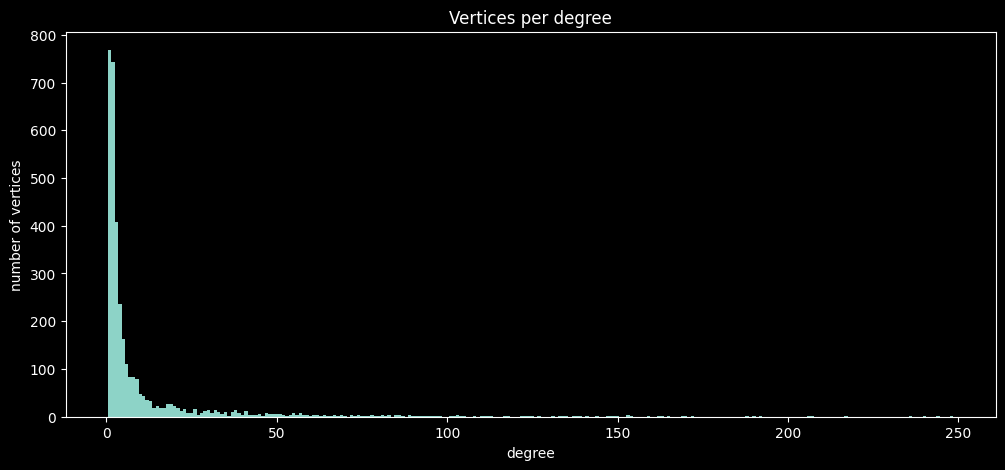

In [ ]:
def vertexCountByDegree(G):
    return pd.Series([d for _, d in G.degree()]).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))

degCounts = vertexCountByDegree(dirGraph)
ax.bar(degCounts.index, degCounts.values, width=1.0)
ax.set(title="Vertices per degree", xlabel="degree", ylabel="number of vertices")

plt.show()

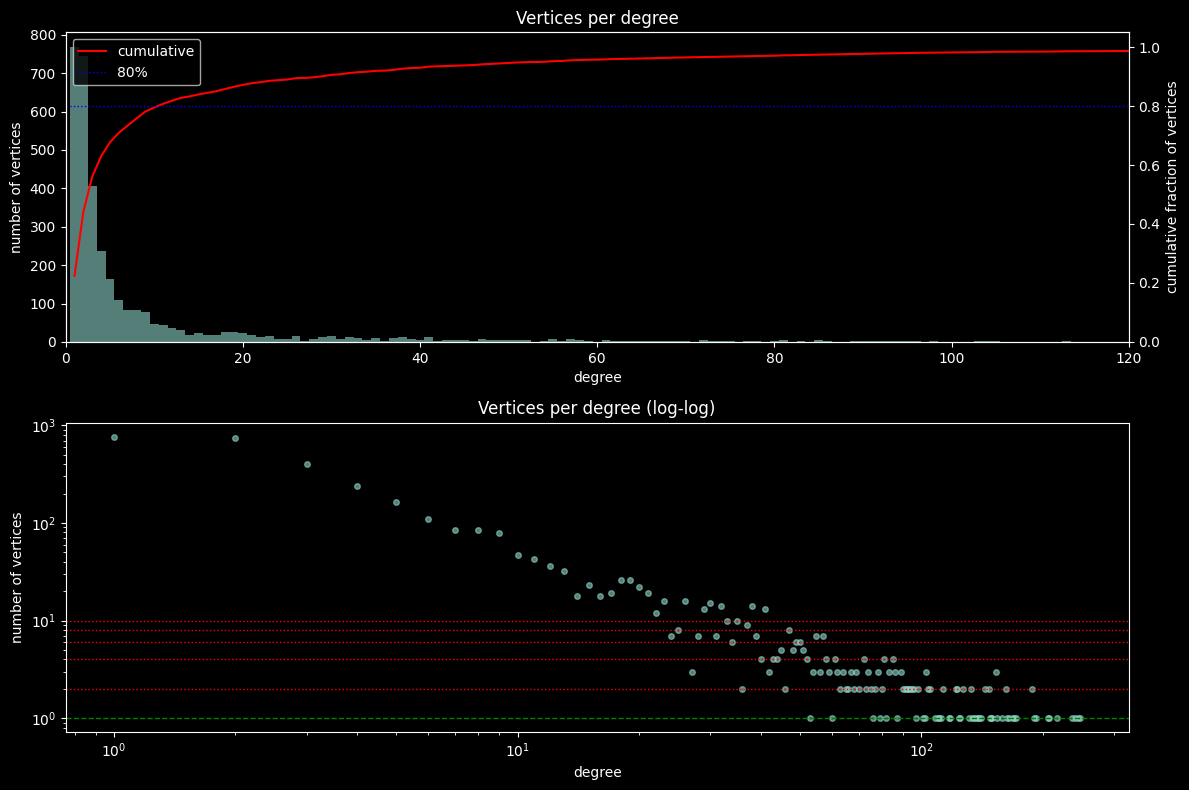

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

degCounts = vertexCountByDegree(dirGraph)
axes[0].bar(degCounts.index, degCounts.values, alpha=0.6, label="original", width=1.0)
axes[0].set(title="Vertices per degree", xlabel="degree", ylabel="number of vertices")
axes[0].set_xlim(0,120)

ax2 = axes[0].twinx()
cum = degCounts.sort_index().cumsum()
ax2.plot(cum.index, cum.values / cum.values[-1], color="red", lw=1.5, label="cumulative")
ax2.axhline(0.8, color="blue",ls=":", lw=1, label="80%")
ax2.set_ylabel("cumulative fraction of vertices")
ax2.set_ylim(0, 1.05)
ax2.legend()

axes[1].loglog(degCounts.index, degCounts.values, "o", ms=4, alpha=0.6, label="original")
axes[1].set(title="Vertices per degree (log-log)", xlabel="degree", ylabel="number of vertices")
for i in range(2,11,2):
    axes[1].axhline(i, color="red", ls=":", lw=1,)
axes[1].axhline(1, color="green", ls="--", lw=1, label="1 vertice")

# for ax in axes:
#     ax.legend()
plt.tight_layout()
plt.show()

### **Exploration of Edges**

In [ ]:
routesDataRaw["frequency"] = routesDataRaw.groupby(["src", "dst"])["src"].transform("size")
uniqueEdges = (
    routesDataRaw.drop(columns=['codeshare','stops', 'frequency'])
    .groupby(by=["src", "dst"])
    .nunique()
)
uniqueEdges["frequency"] = routesDataRaw.groupby(["src", "dst"]).size()

print("no of Edges:", len(uniqueEdges))
display(uniqueEdges)

display(uniqueEdges.loc[('AAE',)])

no of Edges: 37595


airline  airline_id  src_id  dst_id  equipment  frequency
src dst                                                           
AAE ALG        1           1       1       1          1          1
    CDG        1           1       1       1          1          1
    IST        1           1       1       1          1          1
    LYS        1           1       1       1          1          1
    MRS        2           2       1       1          2          2
...          ...         ...     ...     ...        ...        ...
ZYI SZX        1           1       1       1          1          1
    WUH        1           1       1       1          1          1
    XIY        1           1       1       1          1          1
    XMN        1           1       1       1          1          1
ZYL DAC        4           4       1       1          4          4

[37595 rows x 6 columns]

,airline,airline_id,src_id,dst_id,equipment,frequency
dst,,,,,,
ALG,1,1,1,1,1,1
CDG,1,1,1,1,1,1
IST,1,1,1,1,1,1
LYS,1,1,1,1,1,1
MRS,2,2,1,1,2,2
ORN,1,1,1,1,1,1
ORY,2,2,1,1,2,2


In [ ]:
duplicateCount = routesDataRaw[["src", "dst"]].duplicated().sum()
display(duplicateCount)
counts = routesDataRaw[["src", "dst"]].dropna().value_counts()
display(pd.DataFrame(counts))

np.int64(30068)

,,count
src,dst,
ORD,ATL,20
ATL,ORD,19
HKT,BKK,13
ORD,MSY,13
ATL,MIA,12
...,...,...
TSV,WIN,1
WGA,MEL,1
WIN,LRE,1


In [ ]:
query = routesDataRaw[routesDataRaw["src"] == "TSV"]
display(query)

,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment
6912,AA,24.0,TSV,3330.0,BNE,3320.0,Y,0,737
35058,JQ,3052.0,TSV,3330.0,BNE,3320.0,,0,320
35059,JQ,3052.0,TSV,3330.0,MEL,3339.0,,0,321
35060,JQ,3052.0,TSV,3330.0,SYD,3361.0,,0,320
47148,QF,4089.0,TSV,3330.0,BNE,3320.0,,0,73H
47149,QF,4089.0,TSV,3330.0,CNJ,6255.0,Y,0,DH4
47150,QF,4089.0,TSV,3330.0,CNS,3322.0,Y,0,DH3 DH4
47151,QF,4089.0,TSV,3330.0,DRW,3999.0,Y,0,E70
47152,QF,4089.0,TSV,3330.0,ISA,3324.0,Y,0,DH4
47153,QF,4089.0,TSV,3330.0,MKY,3326.0,Y,0,DH4 DH3
